# Quantum vs Classical SVM on the Iris Dataset

**Goal:** classify two Iris species (*setosa* vs *versicolor*) with a classical Support Vector Machine and with a **Quantum Support Vector Machine (QSVM)**, then compare their performance.

**Idea in one paragraph.** An SVM classifies data using a *kernel*, a function that measures how similar two data points are. A classical SVM uses a classical kernel such as RBF. A QSVM replaces it with a **quantum kernel**: each data point is encoded into a quantum state by a circuit (the *feature map*), and the similarity of two points is the overlap (fidelity) of their states. Everything else (the SVM optimisation) stays classical.

**Pipeline**
1. Setup and imports
2. Data: loading, selecting two classes and two features, train/test split, scaling
3. Classical baseline: RBF SVM
4. Quantum feature map and quantum kernel
5. Quantum SVM (QSVC)
6. Comparison of both models
7. Discussion and conclusion

> **Note:** the quantum parts run on a **classical simulator** (no real quantum hardware, no noise), using Qiskit and Qiskit Machine Learning.

## 1. Setup and imports
The next two cells install the required packages (needed on a fresh Colab runtime), followed by the imports.

In [ ]:

# Install all dependencies (needed on a fresh Colab runtime; run once).
# -q = quiet output. qiskit + qiskit-machine-learning provide the quantum circuits,
# kernels and QSVC; scikit-learn provides the data and the classical SVM.
%pip install -q qiskit qiskit-machine-learning scikit-learn matplotlib seaborn pandas


In [ ]:

# pylatexenc is required by Qiskit's matplotlib/LaTeX circuit drawers.
%pip install pylatexenc

In [ ]:
#Import The Libraries
# Numerical arrays, tables and plotting
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# scikit-learn: dataset, train/test split and feature scaling
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

# Classical model: Support Vector Classifier
from sklearn.svm import SVC
# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Libraries imported successfully!")


Libraries imported successfully!


## 2. Data: loading and preparation
Fisher's **Iris dataset** has 150 flowers (50 each of *setosa*, *versicolor* and *virginica*), each described by four measurements in cm: sepal length, sepal width, petal length and petal width.

In [ ]:
#Load The Dataset
# Load the built-in Iris dataset (150 flowers, 3 species, 4 measurements each)
iris = load_iris()

# X: feature matrix of shape (150, 4); y: class labels 0/1/2
X = iris.data
y = iris.target

print("Dataset shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature names:")
print(iris.feature_names)

print("\nClass names:")
print(iris.target_names)


Dataset shape: (150, 4)
Target shape: (150,)

Feature names:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

Class names:
['setosa' 'versicolor' 'virginica']


In [ ]:
#Convert Dataset into DataFrame
# The DataFrame is only for inspection; modelling below uses the NumPy arrays X and y
df = pd.DataFrame(
    X,
    columns=iris.feature_names
)

# Add a readable species column (0/1/2 -> setosa/versicolor/virginica)
df["species"] = [
    iris.target_names[i] for i in y
]

# First 10 rows (all setosa, because the dataset is sorted by class)
df.head(10)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
5,5.4,3.9,1.7,0.4,setosa
6,4.6,3.4,1.4,0.3,setosa
7,5.0,3.4,1.5,0.2,setosa
8,4.4,2.9,1.4,0.2,setosa
9,4.9,3.1,1.5,0.1,setosa


### 2.1 Reduce the problem to 2 classes and 2 features
- **Two classes (*setosa* vs *versicolor*):** a binary classification problem, which is the standard setting for a first QSVM.
- **Two features (petal length and width):** a feature map uses **one qubit per feature**, so two features means a 2-qubit circuit that is quick to simulate. Petal measurements are also the most informative features for separating these species.

In [ ]:
#Select two classes and two features

# Select Setosa and Versicolor only
# Boolean mask keeping classes 0 (setosa) and 1 (versicolor); class 2 is dropped.
# This leaves 100 samples (50 per class).
mask = y < 2

X_binary = X[mask]
y_binary = y[mask]

# Select petal length and petal width (columns 2 and 3).
# Two features = two qubits, which keeps the quantum circuit small and cheap to simulate.
X_selected = X_binary[:, 2:4]

print("Selected dataset shape:", X_selected.shape)
print("Selected labels shape:", y_binary.shape)


Selected dataset shape: (100, 2)
Selected labels shape: (100,)


### 2.2 Train/test split
The data is split 80% for training and 20% for testing. The test set is never used for fitting, so it gives an honest estimate of performance on unseen flowers.

In [ ]:
#Divide the data into training and testing set

# 80/20 split. random_state=42 makes it reproducible; stratify keeps the 50/50 class balance
# in both parts (40+40 for training, 10+10 for testing).
X_train, X_test, y_train, y_test = train_test_split(
    X_selected,
    y_binary,
    test_size=0.2,
    random_state=42,
    stratify=y_binary
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 80
Testing samples: 20


### 2.3 Feature scaling to [0, π]
Quantum feature maps use the feature values as **rotation angles**, so each feature is rescaled to the range [0, π]. The scaler learns its minimum and maximum from the training data only and then applies the same transformation to the test data. This avoids *data leakage*.

In [ ]:
#Normalise the features

# Quantum feature maps encode data as rotation angles, so each feature is rescaled to [0, pi].
# The classical SVM uses the same scaled data, which keeps the comparison fair.
scaler = MinMaxScaler(feature_range=(0, np.pi))

# fit on the TRAINING set only (learns min/max), then transform; this avoids test-set leakage
X_train_scaled = scaler.fit_transform(X_train)
# Test data reuses the training min/max (no refit), so test values may fall slightly outside [0, pi]
X_test_scaled = scaler.transform(X_test)

print("First five scaled training samples:")
print(X_train_scaled[:5])


First five scaled training samples:
[[0.31415927 0.5543987 ]
 [2.98451302 2.58719395]
 [1.88495559 1.66319611]
 [2.67035376 2.58719395]
 [2.67035376 2.58719395]]


### 2.4 Visualise the training data
The two classes form two clearly separated groups, so this is an easy problem. A good classifier should score very high.

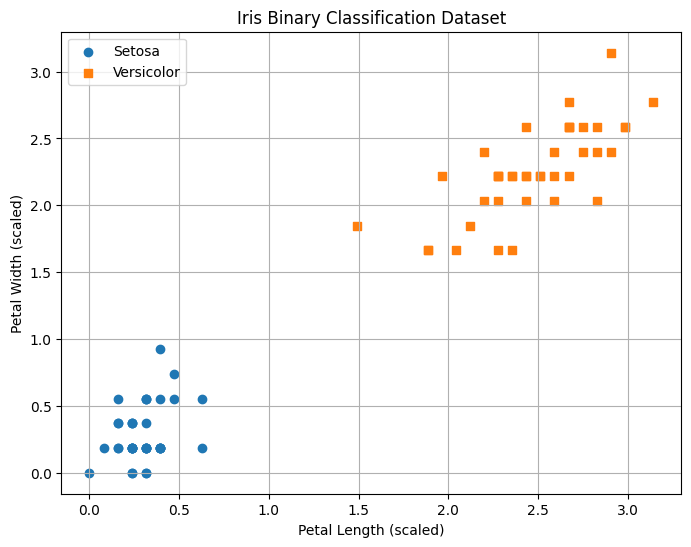

In [ ]:
#Visualise the dataset

# Scatter plot of the two classes in the scaled feature space
plt.figure(figsize=(8, 6))

plt.scatter(
    X_train_scaled[y_train == 0, 0],
    X_train_scaled[y_train == 0, 1],
    label="Setosa",
    marker="o"
)

plt.scatter(
    X_train_scaled[y_train == 1, 0],
    X_train_scaled[y_train == 1, 1],
    label="Versicolor",
    marker="s"
)

# Axis labels, title, legend and grid
plt.xlabel("Petal Length (scaled)")
plt.ylabel("Petal Width (scaled)")
plt.title("Iris Binary Classification Dataset")

plt.legend()
plt.grid(True)
plt.show()


## 3. Classical baseline: RBF SVM
The baseline is a standard scikit-learn `SVC` with an **RBF (Gaussian) kernel**, $k(x, y) = \exp(-\gamma \lVert x - y \rVert^2)$. It is trained on exactly the same scaled data as the quantum model.

In [ ]:

# Create the classical SVM model: RBF (Gaussian) kernel.
# C=1.0 is the regularisation strength; gamma='scale' sets the kernel width automatically from the data.
classical_svm = SVC(kernel="rbf", C=1.0, gamma="scale")

# Train the model
classical_svm.fit(X_train_scaled, y_train)

# Predict the test samples
y_pred_classical = classical_svm.predict(X_test_scaled)

print("Classical SVM predictions:")
print(y_pred_classical)


Classical SVM predictions:
[1 1 1 1 0 0 0 1 0 0 0 1 0 0 0 1 1 0 1 1]


### 3.1 Evaluate the classical model
Metrics reported: **accuracy** (share of correct predictions), **precision** (of the flowers predicted as a class, how many truly belong to it), **recall** (of the flowers truly in a class, how many were found) and **F1** (harmonic mean of precision and recall).

In [ ]:

# Calculate evaluation metrics

# Accuracy = fraction of test samples classified correctly
accuracy = accuracy_score(y_test, y_pred_classical)

# Precision / recall / F1 use average="weighted": computed per class, then averaged
# weighted by class size (both classes have 10 test samples here).
precision = precision_score(
    y_test, y_pred_classical, average="weighted"
)

recall = recall_score(
    y_test, y_pred_classical, average="weighted"
)

f1 = f1_score(
    y_test, y_pred_classical, average="weighted"
)

print("CLASSICAL SVM RESULTS")
print("---------------------")
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)


CLASSICAL SVM RESULTS
---------------------
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0


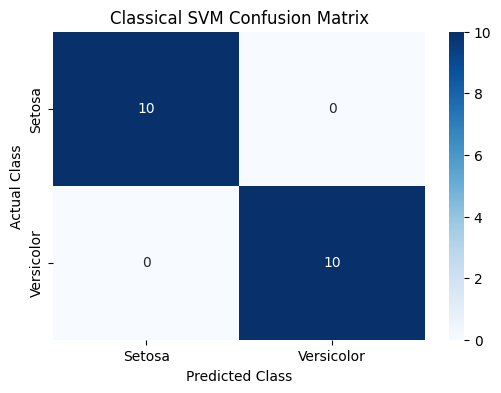

In [ ]:

# Confusion matrix: rows = actual class, columns = predicted class.
# The diagonal holds correct predictions; off-diagonal cells are mistakes.
cm = confusion_matrix(y_test, y_pred_classical)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Setosa", "Versicolor"],
    yticklabels=["Setosa", "Versicolor"]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Classical SVM Confusion Matrix")

plt.show()


In [ ]:
#Save classical results
# (kept in a dict; the comparison table in section 6 is built from these values)
classical_results = {
    "Model": "Classical SVM (RBF)",
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1 Score": f1
}

print(pd.DataFrame([classical_results]))


                 Model  Accuracy  Precision  Recall  F1 Score
0  Classical SVM (RBF)       1.0        1.0     1.0       1.0


## 4. Quantum feature map and quantum kernel

### 4.1 The ZZ feature map
The **ZZ feature map** turns a classical data point $x = (x_0, x_1)$ into a quantum state $|\phi(x)\rangle$ on 2 qubits. One repetition consists of:
1. **Hadamard gates**, which put each qubit into superposition.
2. **Single-qubit phase rotations** by $2x_i$, which encode each feature.
3. **Entangling CNOT gates** plus a **two-qubit phase** $2(\pi - x_0)(\pi - x_1)$, which encode the *interaction* between the features. This is what makes the encoding hard to reproduce with a simple classical formula.

`reps=2` repeats this block twice (a deeper circuit); `entanglement="linear"` entangles neighbouring qubits.

In [ ]:
#Quantum circuit creation (feature map)


# ZZ feature map: a standard data-encoding circuit
# (Havlicek et al., 2019, 'Supervised learning with quantum-enhanced feature spaces', Nature 567)
from qiskit.circuit.library import zz_feature_map

# Number of qubits = number of input features (one qubit per feature)
num_qubits = 2

# Create quantum feature map
feature_map = zz_feature_map(
    feature_dimension=num_qubits,
    # reps = how many times the encoding block is repeated (i.e. circuit depth)
    reps=2, #changing the depth of the quantum feature map affects classification??
    # "linear" entanglement: each qubit is entangled with its neighbour in a chain
    entanglement="linear"
)

# Display circuit
# Draw the circuit as text; x[0] and x[1] are placeholders for the two input features.
# Each repetition = Hadamards -> single-qubit phases 2*x[i] -> CNOT -> two-qubit phase
# 2*(pi - x[0])*(pi - x[1]) -> CNOT.
print(feature_map.decompose().draw("text"))




   ┌────────────┐┌───────────────┐                                         »
0: ┤ U(π/2,0,π) ├┤ U(0,0,2*x[0]) ├──■──────────────────────────────────────»
   ├────────────┤├───────────────┤┌─┴─┐┌──────────────────────────────────┐»
1: ┤ U(π/2,0,π) ├┤ U(0,0,2*x[1]) ├┤ X ├┤ U(0,0,(-π + x[0])*(-π + x[1])*2) ├»
   └────────────┘└───────────────┘└───┘└──────────────────────────────────┘»
«        ┌────────────┐┌───────────────┐     »
«0: ──■──┤ U(π/2,0,π) ├┤ U(0,0,2*x[0]) ├──■──»
«   ┌─┴─┐├────────────┤├───────────────┤┌─┴─┐»
«1: ┤ X ├┤ U(π/2,0,π) ├┤ U(0,0,2*x[1]) ├┤ X ├»
«   └───┘└────────────┘└───────────────┘└───┘»
«                                            
«0: ──────────────────────────────────────■──
«   ┌──────────────────────────────────┐┌─┴─┐
«1: ┤ U(0,0,(-π + x[0])*(-π + x[1])*2) ├┤ X ├
«   └──────────────────────────────────┘└───┘


### 4.2 Encode one flower into the circuit
To see what the feature map does with real data, the first training flower's two scaled values are plugged into the circuit parameters. The numeric angles shown (for example 14.63) are the evaluated gate angles.

In [ ]:
#encode a flower sample

# Select one flower from our training dataset
sample = X_train_scaled[0]

print("Original scaled input:")
print(sample)

# Assign the data values to the circuit parameters
# Map each circuit parameter (x[0], x[1]) to this flower's two scaled feature values
parameter_values = dict(
    zip(feature_map.parameters, sample)
)

# Encode the sample into the quantum circuit
# Bind the numbers to the parameters -> a concrete circuit for this single flower
encoded_circuit = feature_map.assign_parameters(
    parameter_values
)

# Display the encoded circuit
print(encoded_circuit.decompose().draw("text"))


Original scaled input:
[0.31415927 0.5543987 ]
   ┌────────────┐ ┌────────────┐                           ┌────────────┐»
0: ┤ U(π/2,0,π) ├─┤ U(0,0,π/5) ├───■────────────────────■──┤ U(π/2,0,π) ├»
   ├────────────┤┌┴────────────┴┐┌─┴─┐┌──────────────┐┌─┴─┐├────────────┤»
1: ┤ U(π/2,0,π) ├┤ U(0,0,6π/17) ├┤ X ├┤ U(0,0,14.63) ├┤ X ├┤ U(π/2,0,π) ├»
   └────────────┘└──────────────┘└───┘└──────────────┘└───┘└────────────┘»
«    ┌────────────┐                           
«0: ─┤ U(0,0,π/5) ├───■────────────────────■──
«   ┌┴────────────┴┐┌─┴─┐┌──────────────┐┌─┴─┐
«1: ┤ U(0,0,6π/17) ├┤ X ├┤ U(0,0,14.63) ├┤ X ├
«   └──────────────┘└───┘└──────────────┘└───┘


### 4.3 The quantum kernel
The **fidelity quantum kernel** measures similarity between two encoded states:

$$k(x, y) = \left|\langle \phi(x) \,|\, \phi(y) \rangle\right|^2$$

A value of 1 means identical states and a value near 0 means very different states.

In [ ]:

# FidelityQuantumKernel defines k(x, y) = |<phi(x)|phi(y)>|^2, i.e. how similar the two
# quantum states produced by encoding x and y are.
from qiskit_machine_learning.kernels import FidelityQuantumKernel

print("FidelityQuantumKernel imported successfully!")


FidelityQuantumKernel imported successfully!


In [ ]:
#create quantum kernel

# Build the quantum kernel from our feature map. Values range from 0 (very different) to 1 (identical).
# It is evaluated on a classical simulator, not on real quantum hardware.
quantum_kernel = FidelityQuantumKernel(
    feature_map=feature_map
)

print("Quantum kernel created successfully!")


Quantum kernel created successfully!


### 4.4 Kernel matrices
- The **training kernel matrix** (80 × 80) compares every training sample with every other one. The SVM is trained on this matrix.
- The **test kernel matrix** (20 × 80) compares each test sample with every training sample. It is what the trained SVM needs to classify new flowers.

In [ ]:

# Calculate the training kernel matrix
# Gram (kernel) matrix of the training data: entry [i, j] = similarity of training samples i and j.
# Shape (80, 80); the number of entries grows quadratically with the number of samples.
kernel_matrix = quantum_kernel.evaluate(
    x_vec=X_train_scaled
)

print("Kernel matrix shape:", kernel_matrix.shape)

print("\nFirst 5 rows and columns:")
print(kernel_matrix[:5, :5])


Kernel matrix shape: (80, 80)

First 5 rows and columns:
[[1.         0.23510314 0.45960698 0.34977667 0.34977667]
 [0.23510314 1.         0.48765747 0.86653562 0.86653562]
 [0.45960698 0.48765747 1.         0.3988564  0.3988564 ]
 [0.34977667 0.86653562 0.3988564  1.         1.        ]
 [0.34977667 0.86653562 0.3988564  1.         1.        ]]


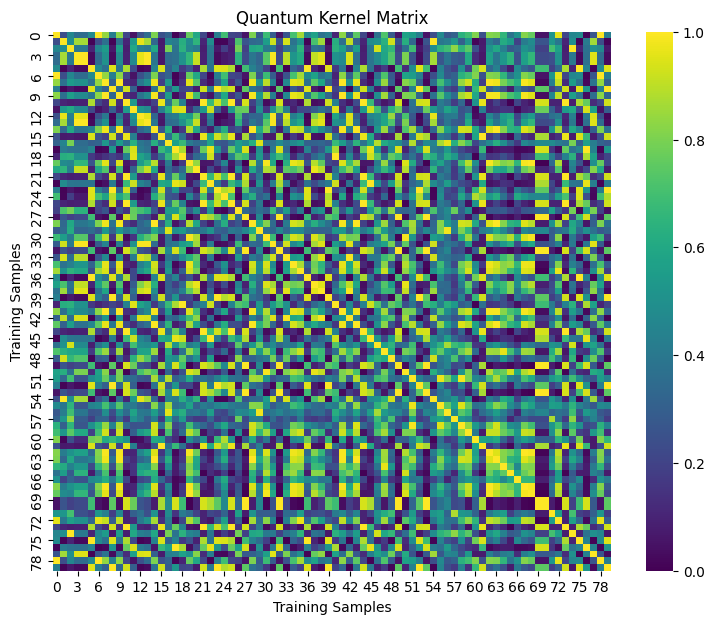

None


In [ ]:
#Visualize

# Heatmap of the training kernel matrix: bright = similar, dark = dissimilar.
# The diagonal is always 1 (a sample is identical to itself). The training data is shuffled,
# so class blocks are not visible here.
plt.figure(figsize=(9, 7))

sns.heatmap(
    kernel_matrix,
    cmap="viridis",
    vmin=0,
    vmax=1
)

plt.title("Quantum Kernel Matrix")
plt.xlabel("Training Samples")
plt.ylabel("Training Samples")

# Note: print() around plt.show() only prints 'None' after the figure; it is harmless.
print(plt.show())


In [ ]:
#Calculate testing kernel matrix
# Rectangular kernel: rows = 20 test samples, columns = 80 training samples.
# Entry [i, j] = similarity of test sample i to training sample j.
# (Computed here to inspect its shape; QSVC.predict() recomputes it internally.)

kernel_test = quantum_kernel.evaluate(
    x_vec=X_test_scaled,
    y_vec=X_train_scaled
)

print("Testing kernel matrix shape:", kernel_test.shape)


Testing kernel matrix shape: (20, 80)


### 4.5 Sanity checks
A valid fidelity kernel must be symmetric, have 1s on the diagonal and contain values between 0 and 1. The checks below confirm this.

In [ ]:
#Verify Quantum Kernel
# A valid fidelity kernel should be symmetric, have 1s on the diagonal and values within [0, 1].
# A maximum of 1.0000000000027 is floating-point rounding error, not a real value above 1.

print("Kernel matrix symmetric:",
      np.allclose(kernel_matrix, kernel_matrix.T))

print("Diagonal values:")
print(np.diag(kernel_matrix)[:10])

print("Minimum kernel value:",
      np.min(kernel_matrix))

print("Maximum kernel value:",
      np.max(kernel_matrix))


Kernel matrix symmetric: True
Diagonal values:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
Minimum kernel value: 0.0007642590041771106
Maximum kernel value: 1.0000000000027154


## 5. Quantum SVM (QSVC)
`QSVC` is a regular scikit-learn SVM that uses the quantum kernel instead of RBF. Training and prediction work like any scikit-learn model: `fit()` then `predict()`.

In [ ]:
#import QSVC
# QSVC = Quantum Support Vector Classifier: a standard scikit-learn SVC that uses the quantum kernel.

from qiskit_machine_learning.algorithms import QSVC

print("QSVC imported successfully!")


QSVC imported successfully!


In [ ]:
#create Quantum SVM model

# Same idea as the classical SVM, but the kernel is the quantum kernel.
# Default regularisation (C=1.0); no hyper-parameter tuning was done.
quantum_svm = QSVC(
    quantum_kernel=quantum_kernel
)

print("Quantum SVM model created successfully!")


Quantum SVM model created successfully!


In [ ]:
#Train Quantum SVM

# fit() first computes the 80x80 training kernel matrix with the circuit simulator,
# then solves the usual SVM optimisation on that matrix.
# Train the Quantum SVM
quantum_svm.fit(X_train_scaled, y_train)

print("Quantum SVM training completed!")


Quantum SVM training completed!


In [ ]:
#Predict the testing samples

# predict() computes the (20 x 80) test-vs-train kernel and classifies each test flower
y_pred_quantum = quantum_svm.predict(X_test_scaled)

print("Quantum SVM Predictions:")
print(y_pred_quantum)

print("\nActual Labels:")
print(y_test)


Quantum SVM Predictions:
[1 1 1 1 0 0 0 1 1 1 0 1 0 0 0 1 1 0 1 1]

Actual Labels:
[1 1 1 1 0 0 0 1 0 0 0 1 0 0 0 1 1 0 1 1]


### 5.1 Evaluate the quantum model
The same metrics as for the classical model are used.

In [ ]:
#Evaluate Quantum SVM (same metrics as the classical model, for a fair comparison)

quantum_accuracy = accuracy_score(
    y_test, y_pred_quantum
)

quantum_precision = precision_score(
    y_test, y_pred_quantum, average="weighted"
)

quantum_recall = recall_score(
    y_test, y_pred_quantum, average="weighted"
)

quantum_f1 = f1_score(
    y_test, y_pred_quantum, average="weighted"
)

print("QUANTUM SVM RESULTS")
print("-------------------")
print("Accuracy:", quantum_accuracy)
print("Precision:", quantum_precision)
print("Recall:", quantum_recall)
print("F1 Score:", quantum_f1)


QUANTUM SVM RESULTS
-------------------
Accuracy: 0.9
Precision: 0.9166666666666667
Recall: 0.9
F1 Score: 0.898989898989899


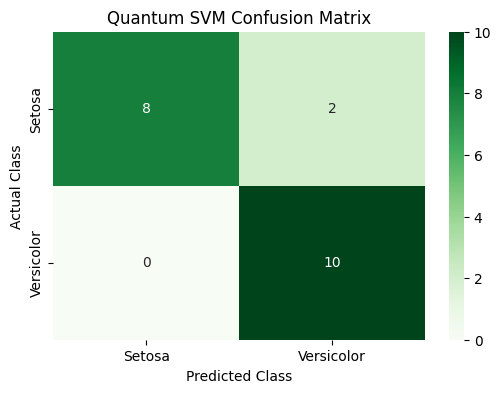

In [ ]:
#Confusion Matrix
# Rows = actual, columns = predicted. In the saved run, the off-diagonal cell shows
# 2 setosa flowers misclassified as versicolor.

cm_quantum = confusion_matrix(
    y_test, y_pred_quantum
)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_quantum,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Setosa", "Versicolor"],
    yticklabels=["Setosa", "Versicolor"]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Quantum SVM Confusion Matrix")

plt.show()


## 6. Comparison: classical vs quantum

In [ ]:
#Compare classical and quantum
# Combine both models' metrics into one table (one row per model).

results = pd.DataFrame([
    {
        "Model": "Classical SVM (RBF)",
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    },
    {
        "Model": "Quantum SVM",
        "Accuracy": quantum_accuracy,
        "Precision": quantum_precision,
        "Recall": quantum_recall,
        "F1 Score": quantum_f1
    }
])

print(results.to_string(index=False))


              Model  Accuracy  Precision  Recall  F1 Score
Classical SVM (RBF)       1.0   1.000000     1.0   1.00000
        Quantum SVM       0.9   0.916667     0.9   0.89899


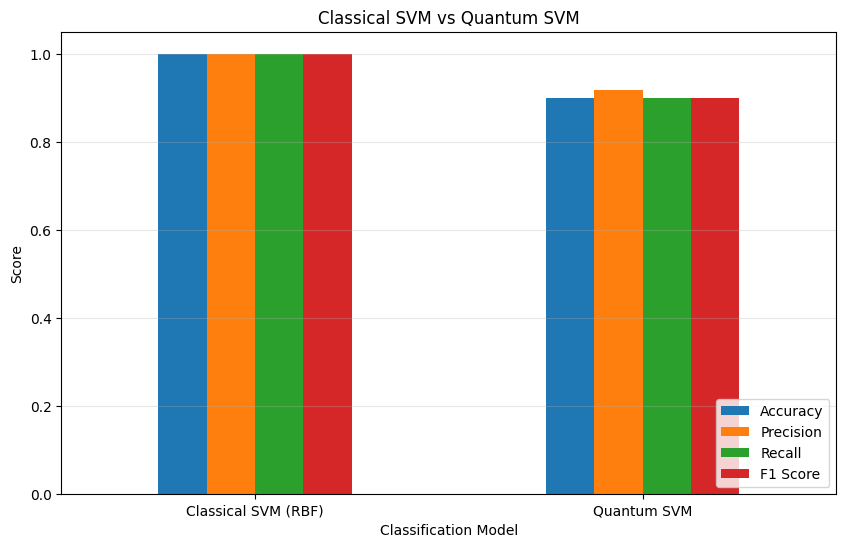

In [ ]:
#Visualization
# Grouped bar chart: one group of bars per model, one colour per metric.

metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

results.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(10, 6),
    ylim=(0, 1.05)
)

plt.title("Classical SVM vs Quantum SVM")
plt.ylabel("Score")
plt.xlabel("Classification Model")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)

plt.show()


## 7. Discussion and conclusion

**Results in this run** (20 test flowers)

| Model | Accuracy | Precision | Recall | F1 |
|---|---|---|---|---|
| Classical SVM (RBF) | 1.00 | 1.000 | 1.00 | 1.000 |
| Quantum SVM | 0.90 | 0.917 | 0.90 | 0.899 |

The classical SVM classified all 20 test flowers correctly. The QSVM got 18 of 20 right; both mistakes are *setosa* flowers predicted as *versicolor*.

**How to interpret this**
- **The difference is not strong evidence.** The test set has only 20 samples from one split, so a single misclassification changes accuracy by 5 percentage points.
- ***Setosa* vs *versicolor* is an easy problem.** The classes are cleanly separable on petal measurements, so the classical baseline is already at the ceiling and there is no room for a quantum advantage to show up. No such advantage is claimed here.
- **The quantum model was not tuned.** It used the default `C = 1.0`, one feature-map choice (`reps=2`, linear entanglement) and one scaling range ([0, π]). Any of these may affect its accuracy.
- **Simulation only.** Results come from an exact classical simulation, so noise from real quantum hardware is not considered.
